# Evolutionary Game Theory

### Learning outcomes


1. Implement and verify a Bayesian Nash Equilibrium in a first-price sealed-bid auction.
2. Model strategy selection with replicator and replicator–mutator dynamics.
3. Analyze equilibria, stability, convergence, and cycles.
4. Implement simple learning dynamics for a multi-agent game.


**Evolutionary Game Theory (EGT)** extends classical game theory by shifting the focus from static, rational decision-making to dynamic, evolving populations of strategies. Originally developed by John Maynard Smith and George R. Price in 1973 to explain animal behaviors, EGT replaces classical concepts like "rational players" and "utility maximization" with biological mechanisms: **phenotypes (strategies)** and **fitness (payoffs)**.

**Key Concepts of EGT**

1. **Strategies as Traits:** Individuals do not choose their strategies rationally; instead, they are born with a programmed strategy (e.g., behaving as a Hawk or a Dove) representing their phenotype.
2. **Fitness and Selection:** The payoff of a strategic interaction represents evolutionary fitness (e.g., survival rate, offspring count). Strategies that yield higher payoffs relative to the population average grow in frequency over time.
3. **Evolutionarily Stable Strategy (ESS):** A strategy (or mixture of strategies) is an ESS if, when adopted by most of the population, it cannot be invaded by any rare mutant strategy.
4. **Replicator Dynamics:** A mathematical model (expressed as differential equations) that describes how the proportions of strategies in a population change over time based on their relative performance.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Fix the seed so that simulation results are reproducible.
SEED = 42
rng = np.random.default_rng(SEED)

NAVY = "#0B2E6D"
ORANGE = "#C65A00"
TEAL = "#008C95"
GREEN = "#18865B"
RED = "#D34841"
PURPLE = "#7158A5"
GRAY = "#66788A"

plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

print("Exercise environment ready.")


Exercise environment ready.


# 1. Bayesian Nash Equilibrium

Consider a first-price sealed-bid auction with $n$ risk-neutral bidders. Each private valuation is independently drawn from $U[0,1]$.

The symmetric BNE strategy is:

$$
b^*(v)=\frac{n-1}{n}v.
$$

## Implement the equilibrium strategy

The code block below defines and implements `equilibrium_bid` to calculate the symmetric Bayesian Nash Equilibrium bid for a given valuation (scalar or array) and bidder count, verifying that inputs are structurally valid.

In [2]:
def equilibrium_bid(
    value: np.ndarray | float,
    n_bidders: int = 2,
) -> np.ndarray:
    """Return the symmetric BNE bid in a uniform first-price auction.

    Parameters
    ----------
    value:
        Private valuation or array of valuations in [0, 1].
    n_bidders:
        Number of bidders; it must be at least two.

    Returns
    -------
    np.ndarray
        Equilibrium bid associated with each valuation.
    """

    # Validate the inputs and implement the analytical formula: b*(v) = ((n - 1) / n) v.
    if n_bidders < 2:
        raise ValueError("The auction must have at least two bidders.")

    values = np.asarray(value, dtype=float)
    if np.any((values < 0) | (values > 1)):
        raise ValueError("This example assumes valuations in [0, 1].")

    return ((n_bidders - 1) / n_bidders) * values

## Verify the best response of every type

Suppose all opponents use the equilibrium strategy. Define:

$$
\alpha=\frac{n-1}{n}.
$$

A candidate bid $b$ wins when every opponent's valuation is below $b/\alpha$. Therefore:

$$
P(\text{win}\mid b)=
\left[\min\left(\frac{b}{\alpha},1\right)\right]^{n-1},
$$

and the expected utility of a bidder with value $v$ is:

$$
EU(b\mid v)=(v-b)P(\text{win}\mid b).
$$

The code block below implements `expected_utility_against_equilibrium` and plots expected utility against a grid of candidate bids to verify that expected utility is maximized at the analytical BNE bidding strategy.

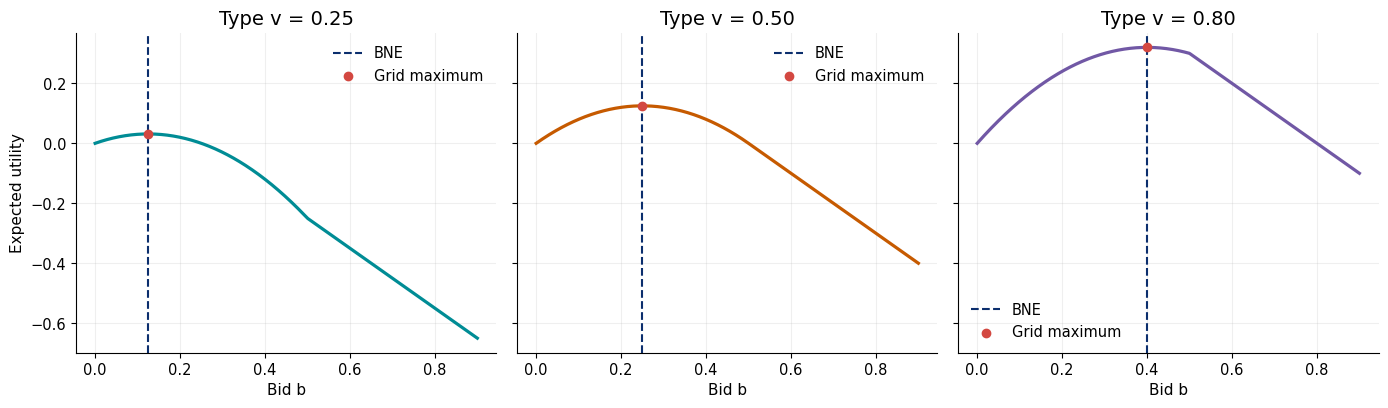

In [3]:
def expected_utility_against_equilibrium(
    bid: np.ndarray | float,
    value: float,
    n_bidders: int = 2,
) -> np.ndarray:
    """Compute expected utility against opponents using the BNE strategy.

    Parameters
    ----------
    bid:
        Candidate bid or array of candidate bids.
    value:
        Player's private valuation in [0, 1].
    n_bidders:
        Total number of bidders.

    Returns
    -------
    np.ndarray
        Expected utility for each candidate bid.
    """

    # Validate inputs, compute the winning probability, and return the expected utility.
    if not 0 <= value <= 1:
        raise ValueError("The valuation must lie in [0, 1].")
    if n_bidders < 2:
        raise ValueError("The auction must have at least two bidders.")

    bids = np.asarray(bid, dtype=float)
    slope = (n_bidders - 1) / n_bidders

    # An opponent bids below b exactly when its valuation is below b / slope.
    probability_one_opponent_loses = np.clip(bids / slope, 0, 1)
    probability_win = probability_one_opponent_loses ** (n_bidders - 1)

    return (value - bids) * probability_win


candidate_bids = np.linspace(0, 0.9, 700)
values_to_check = [0.25, 0.50, 0.80]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

for ax, value, color in zip(axes, values_to_check, [TEAL, ORANGE, PURPLE]):
    utilities = expected_utility_against_equilibrium(
        candidate_bids,
        value=value,
        n_bidders=2,
    )
    numerical_best_bid = candidate_bids[np.argmax(utilities)]
    theoretical_bid = float(equilibrium_bid(value, n_bidders=2))

    ax.plot(candidate_bids, utilities, color=color, linewidth=2.3)
    ax.axvline(theoretical_bid, color=NAVY, linestyle="--", label="BNE")
    ax.scatter(
        [numerical_best_bid],
        [utilities.max()],
        color=RED,
        zorder=3,
        label="Grid maximum",
    )
    ax.set(title=f"Type v = {value:.2f}", xlabel="Bid b")
    ax.grid(alpha=0.2)
    ax.legend()

    assert abs(numerical_best_bid - theoretical_bid) < 0.01

axes[0].set_ylabel("Expected utility")
plt.tight_layout()
plt.show()

## Monte Carlo auction experiment

The following code runs a Monte Carlo simulation of a first-price sealed-bid auction across multiple rounds and bidder pool sizes. It measures efficiency, payments, and utilities to show how competition drives bids closer to true valuations.

### Questions & Answers

1. **How does the equilibrium bid change as the number of bidders increases?**  
   *Answer:* The equilibrium bidding strategy is $b^*(v) = \frac{n-1}{n}v$. As the number of bidders $n$ increases, the scaling factor $\frac{n-1}{n}$ approaches $1$. Bidders bid more aggressively, pushing their bids closer to their actual true valuations to avoid losing.

2. **How do seller revenue and winner utility change?**  
   *Answer:* Seller revenue (the expected winning payment) increases with $n$ because of more aggressive bidding and a higher expected maximum valuation. Conversely, the expected winner utility decreases towards $0$ as intense competition squeezes the margin between the winning bid and valuation.

3. **Why is allocation efficient when all bidders use a strictly increasing bidding strategy?**  
   *Answer:* Since the equilibrium bid function $b^*(v)$ is strictly increasing in valuation $v$, the ordering of the bids is identical to the ordering of the valuations. The bidder with the highest valuation always submits the highest bid, guaranteeing that the item is allocated to the participant who values it most.

In [4]:
def simulate_first_price_auction(
    rounds: int = 20_000,
    n_bidders: int = 2,
    seed: int = SEED,
) -> pd.DataFrame:
    """Simulate first-price auctions under the symmetric BNE strategy.

    Parameters
    ----------
    rounds:
        Number of independent auctions.
    n_bidders:
        Number of bidders in every auction.
    seed:
        Random seed.

    Returns
    -------
    pd.DataFrame
        Winning value, payment, winner utility, and allocation efficiency.
    """

    # Validate conditions, draw random uniform valuations, and compute active bids and winners.
    if rounds <= 0:
        raise ValueError("The number of rounds must be positive.")
    if n_bidders < 2:
        raise ValueError("The auction must have at least two bidders.")

    local_rng = np.random.default_rng(seed)
    values = local_rng.uniform(0, 1, size=(rounds, n_bidders))
    bids = equilibrium_bid(values, n_bidders=n_bidders)

    winners = np.argmax(bids, axis=1)
    row_indices = np.arange(rounds)
    winning_values = values[row_indices, winners]
    winning_bids = bids[row_indices, winners]
    highest_value_indices = np.argmax(values, axis=1)

    return pd.DataFrame({
        "Winning value": winning_values,
        "Payment": winning_bids,
        "Winner utility": winning_values - winning_bids,
        "Efficient allocation": winners == highest_value_indices,
    })


summary_rows = []
for number_of_bidders in [2, 3, 5, 10]:
    results = simulate_first_price_auction(
        rounds=20_000,
        n_bidders=number_of_bidders,
        seed=SEED + number_of_bidders,
    )
    summary_rows.append({
        "Bidders": number_of_bidders,
        "Mean payment": results["Payment"].mean(),
        "Mean winner utility": results["Winner utility"].mean(),
        "Efficient allocation": results["Efficient allocation"].mean(),
    })

auction_comparison = pd.DataFrame(summary_rows)
display(auction_comparison.style.format({
    "Mean payment": "{:.4f}",
    "Mean winner utility": "{:.4f}",
    "Efficient allocation": "{:.4f}",
}))

assert (auction_comparison["Efficient allocation"] > 0.999).all()

,Bidders,Mean payment,Mean winner utility,Efficient allocation
0,2,0.3336,0.3336,1.0000
1,3,0.4991,0.2495,1.0000
2,5,0.6666,0.1666,1.0000
3,10,0.8174,0.0908,1.0000


# 2. Evolutionary Game Theory

Consider the Hawk–Dove game with resource value $V$ and conflict cost $C>V$.

If $x$ is the Hawk share, the expected payoffs are:

$$
f_H(x)=x\frac{V-C}{2}+(1-x)V,
$$

$$
f_D(x)=(1-x)\frac{V}{2},
$$

and the population average is:

$$
\bar f(x)=xf_H(x)+(1-x)f_D(x).
$$

Replicator dynamics is:

$$
\dot{x}=x\left(f_H(x)-\bar f(x)
\right).
$$

## Payoffs and the dynamic field

The code block below implements the payoff calculations and the right-hand side differential equation `hawk_dove_rhs` describing the population's rate of change over time.

In [5]:
RESOURCE_VALUE = 2.0
CONFLICT_COST = 4.0


def hawk_dove_payoffs(
    hawk_share: np.ndarray | float,
    resource_value: float = RESOURCE_VALUE,
    conflict_cost: float = CONFLICT_COST,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return Hawk, Dove, and average population payoffs.

    Parameters
    ----------
    hawk_share:
        Current proportion of Hawks in [0, 1].
    resource_value:
        Resource value V.
    conflict_cost:
        Conflict cost C.

    Returns
    -------
    tuple[np.ndarray, np.ndarray, np.ndarray]
        Hawk payoff, Dove payoff, and average payoff.
    """

    # Validate inputs and compute the corresponding payoffs for Hawks, Doves, and the average population.
    x = np.asarray(hawk_share, dtype=float)
    if np.any((x < 0) | (x > 1)):
        raise ValueError("The Hawk share must lie in [0, 1].")
    if resource_value <= 0 or conflict_cost <= 0:
        raise ValueError("V and C must be positive.")

    payoff_hawk = (
        x * ((resource_value - conflict_cost) / 2)
        + (1 - x) * resource_value
    )
    payoff_dove = (1 - x) * (resource_value / 2)
    average_payoff = x * payoff_hawk + (1 - x) * payoff_dove

    return payoff_hawk, payoff_dove, average_payoff


def hawk_dove_rhs(
    hawk_share: float,
    resource_value: float = RESOURCE_VALUE,
    conflict_cost: float = CONFLICT_COST,
) -> float:
    """Return dx/dt for Hawk–Dove replicator dynamics.

    Parameters
    ----------
    hawk_share:
        Current Hawk share.
    resource_value:
        Resource value V.
    conflict_cost:
        Conflict cost C.

    Returns
    -------
    float
        Rate of change of the Hawk share.
    """

    # Calculate the rate of population change by evaluating fitness relative to the average population.
    payoff_hawk, _, average_payoff = hawk_dove_payoffs(
        hawk_share,
        resource_value,
        conflict_cost,
    )
    return float(hawk_share * (payoff_hawk - average_payoff))

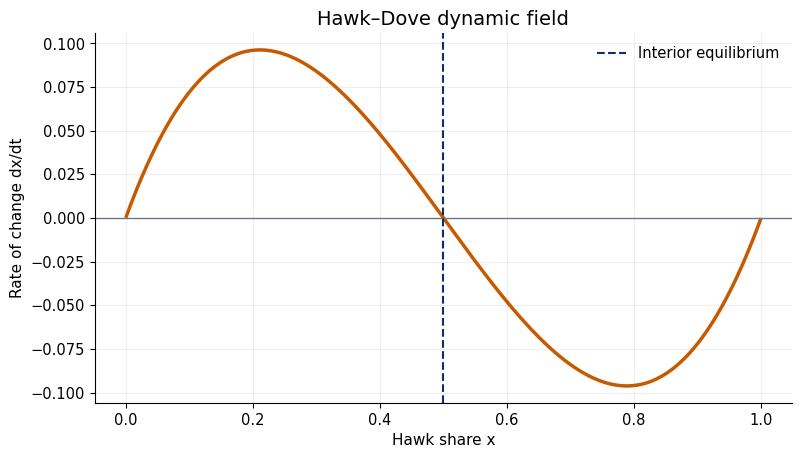

In [6]:
# Run this cell to evaluate fitness values and rates of change.
hawk_payoff, dove_payoff, average_payoff = hawk_dove_payoffs(0.5)

shares = np.linspace(0.001, 0.999, 500)
change_rates = np.array([hawk_dove_rhs(x) for x in shares])

fig, ax = plt.subplots()
ax.plot(shares, change_rates, color=ORANGE, linewidth=2.5)
ax.axhline(0, color=GRAY, linewidth=1)
ax.axvline(
    RESOURCE_VALUE / CONFLICT_COST,
    color=NAVY,
    linestyle="--",
    label="Interior equilibrium",
)
ax.set(
    xlabel="Hawk share x",
    ylabel="Rate of change dx/dt",
    title="Hawk–Dove dynamic field",
)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## Simulate convergence to the ESS

The code block below simulates the evolutionary trajectories using the RK4 integration method to demonstrate how different starting shares of Hawks and Doves dynamically converge to the stable interior Evolutionarily Stable Strategy of $x^* = 0.5$.

### Analysis question & Answer

**Is every equilibrium necessarily stable?**

*Answer:* No, not every equilibrium is stable. In the Hawk-Dove game, there are three equilibria: $x^* = 0$, $x^* = 1$, and $x^* = V/C = 0.5$ (when $C > V$).
* At the boundary equilibrium $x^* = 0$, any small positive perturbation to $x > 0$ yields $\dot{x} > 0$ (since Hawks outperform Doves initially), which pushes the state further away from $0$. Thus, $x^* = 0$ is unstable.
* At the boundary equilibrium $x^* = 1$, any small downward perturbation to $x < 1$ yields $\dot{x} < 0$ (since Doves outperform Hawks under pure conflict), which pushes the state further away from $1$. Thus, $x^* = 1$ is unstable.
* At the interior equilibrium $x^* = 0.5$, if $x < 0.5$ then $\dot{x} > 0$, and if $x > 0.5$ then $\dot{x} < 0$. The signs of the derivative always point back toward $x^*$, making this equilibrium stable.

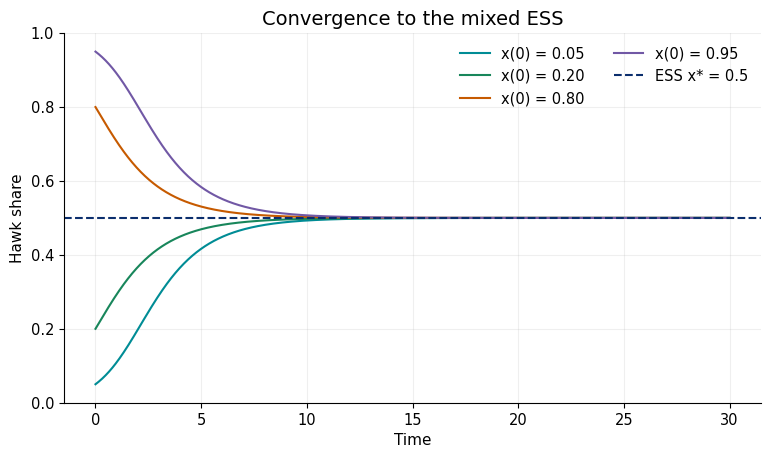

In [7]:
def simulate_hawk_dove(
    initial_hawk_share: float,
    dt: float = 0.02,
    steps: int = 1_500,
    resource_value: float = RESOURCE_VALUE,
    conflict_cost: float = CONFLICT_COST,
) -> tuple[np.ndarray, np.ndarray]:
    """Simulate Hawk–Dove replicator dynamics with Euler integration.

    Parameters
    ----------
    initial_hawk_share:
        Initial Hawk share.
    dt:
        Time-step size.
    steps:
        Number of integration steps.
    resource_value:
        Resource value V.
    conflict_cost:
        Conflict cost C.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Time values and Hawk-share trajectory.
    """

    # Check initial conditions, allocate memory, and step through time using RK4 integration.
    if not 0 < initial_hawk_share < 1:
        raise ValueError("The initial share must be strictly between zero and one.")
    if dt <= 0 or steps <= 0:
        raise ValueError("dt and steps must be positive.")

    time = np.arange(steps + 1) * dt
    trajectory = np.empty(steps + 1)
    trajectory[0] = initial_hawk_share

    # RK4 provides smooth trajectories while preserving good numerical accuracy.
    for index in range(steps):
        x = trajectory[index]
        k1 = hawk_dove_rhs(x, resource_value, conflict_cost)
        k2 = hawk_dove_rhs(x + 0.5 * dt * k1, resource_value, conflict_cost)
        k3 = hawk_dove_rhs(x + 0.5 * dt * k2, resource_value, conflict_cost)
        k4 = hawk_dove_rhs(x + dt * k3, resource_value, conflict_cost)
        next_x = x + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
        trajectory[index + 1] = np.clip(next_x, 0, 1)

    return time, trajectory


initial_conditions = [0.05, 0.20, 0.80, 0.95]
fig, ax = plt.subplots()

for initial_share, color in zip(
    initial_conditions,
    [TEAL, GREEN, ORANGE, PURPLE],
):
    time, trajectory = simulate_hawk_dove(initial_share)
    ax.plot(time, trajectory, color=color, label=f"x(0) = {initial_share:.2f}")
    assert abs(trajectory[-1] - 0.5) < 0.02

ax.axhline(0.5, color=NAVY, linestyle="--", label="ESS x* = 0.5")
ax.set(
    xlabel="Time",
    ylabel="Hawk share",
    title="Convergence to the mixed ESS",
    ylim=(0, 1),
)
ax.legend(ncol=2)
ax.grid(alpha=0.2)
plt.show()

## Replicator–mutator extension

For symmetric mutation between Hawk and Dove, add:

$$
\mu(1-2x)
$$

to the standard replicator equation:

$$
\dot{x}
=
x\left(f_H-\bar f\right)+\mu(1-2x).
$$

The code below implements `hawk_dove_mutator_rhs` to calculate the modified derivative accounting for symmetric genetic mutation or strategy switching.

### Question & Answer

**In this symmetric example, does mutation change the equilibrium location, the convergence speed, or both?**  

*Answer:* In this symmetric case, mutation changes **only the convergence speed, not the equilibrium location**. Because the game is perfectly symmetric with $x^* = 0.5$, the mutation term $\mu(1 - 2x)$ becomes $0$ exactly at $x = 0.5$. Thus, $x^* = 0.5$ remains the equilibrium. However, the extra term increases the magnitude of $|\dot{x}|$ on both sides of the equilibrium, pulling the population back faster and accelerating convergence.

In [8]:
def hawk_dove_mutator_rhs(
    hawk_share: float,
    mutation_rate: float,
) -> float:
    """Return the Hawk-share derivative with symmetric mutation.

    Parameters
    ----------
    hawk_share:
        Current Hawk share.
    mutation_rate:
        Symmetric mutation rate between Hawk and Dove.

    Returns
    -------
    float
        Replicator–mutator rate of change.
    """

    # Combine the standard replicator growth term with the symmetric mutation restoring term.
    replicator_term = hawk_dove_rhs(hawk_share)
    mutator_term = mutation_rate * (1 - 2 * hawk_share)
    return replicator_term + mutator_term

# 3. Game Dynamics

Consider Rock–Paper–Scissors:

$$
A=
\begin{bmatrix}
0 & -1 & 1\\
1 & 0 & -1\\
-1 & 1 & 0
\end{bmatrix}.
$$

The symmetric mixed Nash equilibrium is:

$$
x^*=\left(\frac13,\frac13,\frac13
\right).
$$

Replicator dynamics is:

$$
\dot{x}_i=x_i
\left((Ax)_i-x^\top Ax\right).
$$

## Implement and simulate RPS dynamics

The code cell below defines multi-strategy replicator equations and solves them on a probability simplex using integration with optional mutation regularization to compare standard cyclic orbits and damped stable spirals.

In [9]:
RPS_PAYOFF = np.array([
    [0.0, -1.0, 1.0],
    [1.0, 0.0, -1.0],
    [-1.0, 1.0, 0.0],
])


def replicator_rhs(
    state: np.ndarray,
    payoff_matrix: np.ndarray,
    mutation_rate: float = 0.0,
) -> np.ndarray:
    """Return the replicator derivative for a multi-strategy game.

    Parameters
    ----------
    state:
        Strategy distribution.
    payoff_matrix:
        Square payoff matrix.
    mutation_rate:
        Regularization strength toward the uniform distribution.

    Returns
    -------
    np.ndarray
        Rate of change of every strategy share.
    """

    # Compute individual strategy payoffs, the weighted average, and apply mutation regularizer.
    x = np.asarray(state, dtype=float)
    matrix = np.asarray(payoff_matrix, dtype=float)

    if matrix.shape != (x.size, x.size):
        raise ValueError("The payoff matrix must be square and match the state.")
    if mutation_rate < 0:
        raise ValueError("mutation_rate cannot be negative.")

    payoffs = matrix @ x
    average_payoff = float(x @ payoffs)
    change = x * (payoffs - average_payoff)

    # Mutation prevents permanent strategy extinction and adds a restoring force.
    if mutation_rate > 0:
        uniform_state = np.full_like(x, 1 / x.size)
        change = change + mutation_rate * (uniform_state - x)

    return change


def simulate_simplex_dynamics(
    initial_state: np.ndarray,
    payoff_matrix: np.ndarray,
    dt: float = 0.02,
    steps: int = 5_000,
    mutation_rate: float = 0.0,
) -> tuple[np.ndarray, np.ndarray]:
    """Simulate replicator dynamics on a probability simplex.

    Parameters
    ----------
    initial_state:
        Initial probability distribution over strategies.
    payoff_matrix:
        Payoff matrix.
    dt:
        Time-step size.
    steps:
        Number of Euler steps.
    mutation_rate:
        Regularization strength.

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Time values and strategy-distribution trajectory.
    """

    # Integrate the derivatives over time and project onto the simplex to fix float drift.
    state = np.asarray(initial_state, dtype=float)
    if np.any(state < 0) or not np.isclose(state.sum(), 1):
        raise ValueError("initial_state must be a probability distribution.")
    if dt <= 0 or steps <= 0:
        raise ValueError("dt and steps must be positive.")

    time = np.arange(steps + 1) * dt
    trajectory = np.empty((steps + 1, state.size))
    trajectory[0] = state

    for index in range(steps):
        x = trajectory[index]
        k1 = replicator_rhs(x, payoff_matrix, mutation_rate)
        k2 = replicator_rhs(x + 0.5 * dt * k1, payoff_matrix, mutation_rate)
        k3 = replicator_rhs(x + 0.5 * dt * k2, payoff_matrix, mutation_rate)
        k4 = replicator_rhs(x + dt * k3, payoff_matrix, mutation_rate)

        next_state = x + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)

        # Correct floating-point drift so the trajectory remains on the simplex.
        next_state = np.clip(next_state, 1e-12, None)
        trajectory[index + 1] = next_state / next_state.sum()

    return time, trajectory

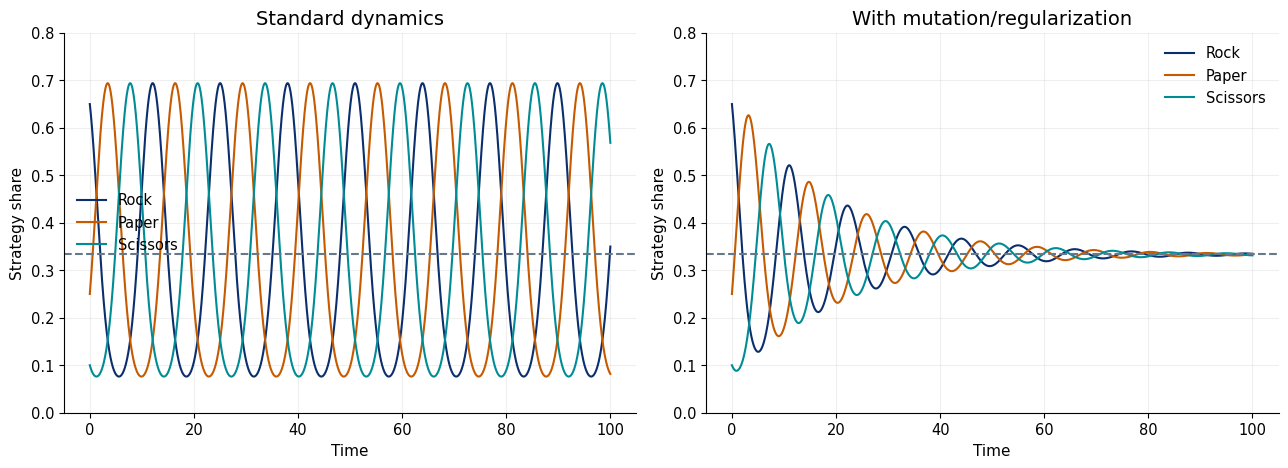

Final L1 distance without mutation: 0.5033
Final L1 distance with mutation:    0.0039


In [10]:
initial_rps = np.array([0.65, 0.25, 0.10])
nash_rps = np.full(3, 1 / 3)

time_cycle, trajectory_cycle = simulate_simplex_dynamics(
    initial_rps,
    RPS_PAYOFF,
    mutation_rate=0.0,
)
time_stable, trajectory_stable = simulate_simplex_dynamics(
    initial_rps,
    RPS_PAYOFF,
    mutation_rate=0.05,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
labels = ["Rock", "Paper", "Scissors"]
colors = [NAVY, ORANGE, TEAL]

for index, (label, color) in enumerate(zip(labels, colors)):
    axes[0].plot(time_cycle, trajectory_cycle[:, index], color=color, label=label)
    axes[1].plot(time_stable, trajectory_stable[:, index], color=color, label=label)

axes[0].set_title("Standard dynamics")
axes[1].set_title("With mutation/regularization")

for ax in axes:
    ax.axhline(1 / 3, color=GRAY, linestyle="--")
    ax.set(xlabel="Time", ylabel="Strategy share", ylim=(0, 0.8))
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

distance_cycle = np.abs(trajectory_cycle - nash_rps).sum(axis=1)
distance_stable = np.abs(trajectory_stable - nash_rps).sum(axis=1)

print(f"Final L1 distance without mutation: {distance_cycle[-1]:.4f}")
print(f"Final L1 distance with mutation:    {distance_stable[-1]:.4f}")

## Fictitious Play

The following code models Fictitious Play learning dynamics for zero-sum Rock-Paper-Scissors. In each round, players update empirical beliefs about opponents and select a best response, showing how cumulative frequencies converge to the Nash equilibrium even as individual actions cycle.

### Questions & Answers

1. **Do individual actions converge?**  
   *Answer:* No. Because players always select pure best responses to their beliefs, individual actions continue to jump back and forth between Rock, Paper, and Scissors, forming cyclic patterns.

2. **Do empirical frequencies converge?**  
   *Answer:* Yes. While actions cycle, the running average (the cumulative empirical frequencies of play) slowly converges to the symmetric Nash Equilibrium proportions of $(\frac{1}{3}, \frac{1}{3}, \frac{1}{3})$ as the number of rounds $t \to \infty$.

3. **How does this result differ from the standard replicator trajectory?**  
   *Answer:* Under standard replicator dynamics, the system remains in a perpetual orbit with a constant distance from the equilibrium, never getting any closer. Under Fictitious Play, the empirical strategy frequency actually converges to the Nash Equilibrium as the cycles become tighter in terms of cumulative average frequency (converging at a rate of $O(t^{-1/2})$).

In [11]:
def simulate_fictitious_play(
    payoff_matrix: np.ndarray,
    rounds: int = 4_000,
    seed: int = SEED,
) -> pd.DataFrame:
    """Simulate Fictitious Play in a two-player zero-sum game.

    Parameters
    ----------
    payoff_matrix:
        Row player's payoff matrix.
    rounds:
        Number of learning rounds.
    seed:
        Random seed for tie-breaking.

    Returns
    -------
    pd.DataFrame
        Empirical row-player frequencies and distance to Nash.
    """

    # Update action beliefs, calculate expected payoffs for actions, and choose the best response.
    matrix = np.asarray(payoff_matrix, dtype=float)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("This example requires a square payoff matrix.")
    if rounds <= 0:
        raise ValueError("The number of rounds must be positive.")

    local_rng = np.random.default_rng(seed)
    number_of_actions = matrix.shape[0]

    # Unit pseudocounts create uniform initial beliefs and avoid division by zero.
    row_counts = np.ones(number_of_actions)
    column_counts = np.ones(number_of_actions)
    history = np.empty((rounds, number_of_actions))

    for round_index in range(rounds):
        belief_about_column = column_counts / column_counts.sum()
        belief_about_row = row_counts / row_counts.sum()

        row_payoffs = matrix @ belief_about_column
        column_payoffs = -(belief_about_row @ matrix)

        row_best = np.flatnonzero(np.isclose(row_payoffs, row_payoffs.max()))
        column_best = np.flatnonzero(np.isclose(column_payoffs, column_payoffs.max()))

        row_action = local_rng.choice(row_best)
        column_action = local_rng.choice(column_best)

        row_counts[row_action] += 1
        column_counts[column_action] += 1
        history[round_index] = row_counts / row_counts.sum()

    result = pd.DataFrame(history, columns=["Rock", "Paper", "Scissors"])
    result["Round"] = np.arange(1, rounds + 1)
    result["L1 distance to Nash"] = np.abs(
        history - np.full(number_of_actions, 1 / number_of_actions)
    ).sum(axis=1)

    return result

In [14]:
# Return the dataframe
rps_ff = simulate_fictitious_play(RPS_PAYOFF)
display(rps_ff.head(10))
display(rps_ff.tail(10))

,Rock,Paper,Scissors,Round,L1 distance to Nash
0,0.500000,0.250000,0.250000,1,0.333333
1,0.600000,0.200000,0.200000,2,0.533333
2,0.500000,0.166667,0.333333,3,0.333333
3,0.428571,0.142857,0.428571,4,0.380952
4,0.375000,0.125000,0.500000,5,0.416667
5,0.333333,0.111111,0.555556,6,0.444444
6,0.300000,0.200000,0.500000,7,0.333333
7,0.272727,0.272727,0.454545,8,0.242424
8,0.250000,0.333333,0.416667,9,0.166667
9,0.230769,0.384615,0.384615,10,0.205128


,Rock,Paper,Scissors,Round,L1 distance to Nash
3990,0.335253,0.324487,0.340260,3991,0.017693
3991,0.335169,0.324406,0.340426,3992,0.017856
3992,0.335085,0.324324,0.340591,3993,0.018018
3993,0.335001,0.324243,0.340756,3994,0.018180
3994,0.334917,0.324162,0.340920,3995,0.018343
3995,0.334834,0.324081,0.341085,3996,0.018505
3996,0.334750,0.324000,0.341250,3997,0.018667
3997,0.334666,0.323919,0.341415,3998,0.018829
3998,0.334583,0.323838,0.341579,3999,0.018991
3999,0.334499,0.323757,0.341744,4000,0.019152


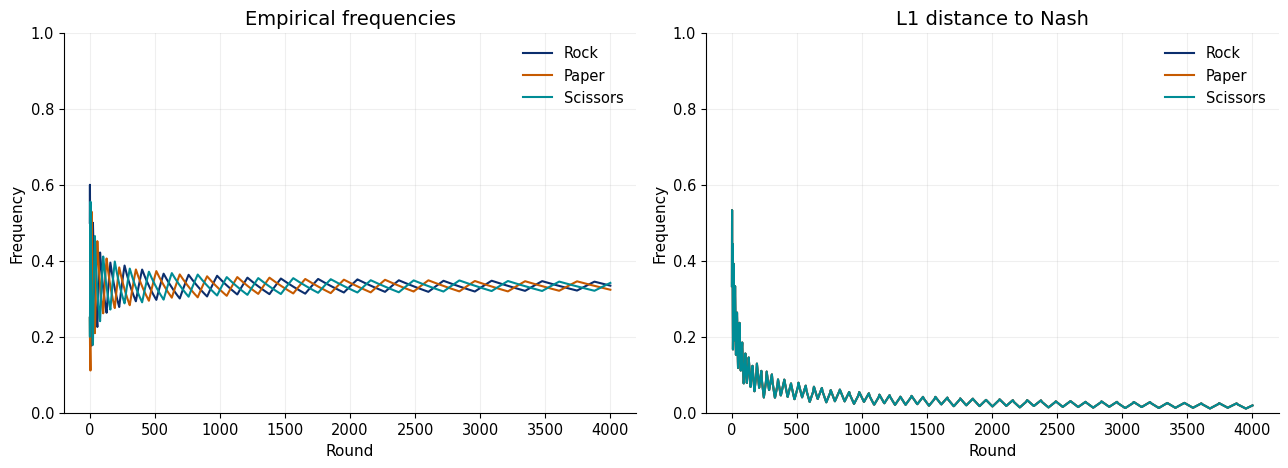

In [12]:
# Simulate
rps_ff = simulate_fictitious_play(RPS_PAYOFF)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
labels = ["Rock", "Paper", "Scissors"]
colors = [NAVY, ORANGE, TEAL]

for index, (label, color) in enumerate(zip(labels, colors)):
    axes[0].plot(rps_ff["Round"], rps_ff[label], color=color, label=label)
    axes[1].plot(rps_ff["Round"], rps_ff["L1 distance to Nash"], color=color, label=label)

axes[0].set_title("Empirical frequencies")
axes[1].set_title("L1 distance to Nash")

for ax in axes:
    ax.set(xlabel="Round", ylabel="Frequency", ylim=(0, 1))
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Synthesis questions


1. Why is a Bayesian strategy a mapping from types to actions rather than a single action?

**Answer:** Players have incomplete information and do not know their opponents' exact private values (types). A player must decide their action conditional on their own private information. Therefore, a strategy must specify an optimal action for every possible private type they might receive.

2. In the auction, why does the winning bid increase with the number of bidders?

**Answer:** As the number of bidders ($n$) increases, competition intensifies. Mathematically, the BNE strategy is $b^*(v) = \frac{n-1}{n}v$, which is strictly increasing in $n$. Additionally, with more bidders, the expected value of the highest valuation (the first-order statistic) increases, leading to a higher winning valuation and thus a higher winning payment.

3. Why is $x^*=V/C$ stable in Hawk–Dove when $C>V$?

**Answer:** If the fraction of Hawks $x$ is slightly above $x^*$, the Hawk payoff drops below the Dove payoff ($f_H < f_D$), causing the Hawk population share to decrease ($\dot{x} < 0$) back toward $x^*$. Conversely, if $x$ is below $x^*$, Hawks earn more than Doves ($f_H > f_D$), driving $\dot{x} > 0$ and pulling the state back up to $x^*$. This negative feedback loop makes it a stable Evolutionarily Stable Strategy (ESS).

4. Give an example of an equilibrium that is not dynamically attractive.

**Answer:** In the standard Rock-Paper-Scissors game under replicator dynamics, the symmetric mixed Nash equilibrium $x^* = (1/3, 1/3, 1/3)$ is a center (neutral equilibrium) but not an attractor; any interior trajectory starting away from it will cycle around it forever on a closed orbit rather than converging to it.

5. Why can simultaneous learning by multiple agents create a non-stationary environment?

**Answer:** Because as each agent updates their strategy, they change the transition probabilities and payoffs of the other agents. Since everyone is adapting at the same time, the environment (the distribution of opponent actions) is constantly shifting, violating the stationary environment assumption required for traditional single-agent reinforcement learning.

6. Compare mutation, regularization, and exploration in the three models.

**Answer:** All three introduce a restoring force that prevents strategy extinction and drives players away from extreme, pure strategies. In Hawk-Dove, mutation acts as a drift parameter; in RPS replicator dynamics, regularization pulls the strategy shares toward the uniform state (damping the cycles into stable spirals); in Fictitious Play, the initial pseudocounts act as regularization (prior belief) that smooths early action selection.

7. Which experiment best demonstrates that “equilibrium exists” does not imply “learning converges”?

**Answer:** The zero-sum Rock-Paper-Scissors game under standard replicator dynamics. Although a unique symmetric Nash equilibrium exists at $(1/3, 1/3, 1/3)$, the learning trajectory does not converge to this point, but instead enters a non-convergent, undamped periodic cycle.